
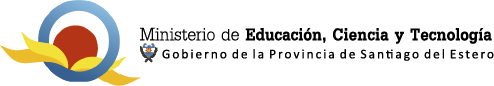

# Clase 5: Deep Learning con Keras. TP2

## Materia: Sistemas de Inteligencia Artificial

## Contenidos:

* Modelos de Clasificación con Keras

## Docente: Dr. Marcos A. Argañaraz - Juana López

## Introducción


En este laboratorio, aprenderemos cómo usar la librería Keras para construir modelos para problemas de clasificación. Usaremos el popular conjunto de datos MNIST, un conjunto de datos de imágenes, para variar.

La <strong>base de datos MNIST</strong>, acrónimo de Modified National Institute of Standards and Technology, es una gran base de datos de dígitos manuscritos que se utiliza comúnmente para entrenar diversos sistemas de procesamiento de imágenes. La base de datos también se utiliza ampliamente para el entrenamiento y la prueba en el campo del aprendizaje automático.
    
La base de datos MNIST contiene 60,000 imágenes de entrenamiento y 10,000 imágenes de prueba de dígitos escritos por estudiantes de secundaria y empleados de la Oficina del Censo de los Estados Unidos.

Además, de esta manera, podrás comparar cómo se comparan las redes neuronales convencionales con las redes neuronales convolucionales, que construiremos en el siguiente módulo.


## Objetivos de este Notebook
* Utiliza la base de datos MNIST para entrenar varios sistemas de procesamiento de imágenes.
* Construir una red neuronal
* Entrenar y probar la red


## Tabla de Contenidos

<div class="alert alert-block alert-info" style="margin-top: 20px">

<font size = 3>

1. <a href="#Importar-Keras-y-Paquetes">Importar Keras y Paquetes</a>
2. <a href="#Construir-una-Rede-Neuronal">Construir una Red Neuronal</a>
3. <a href="#Entrenar-y-Probar-la-Rede">Entrenar y Probar la Red</a>  

</fuente>
</div>


Comencemos instalando Keras y otras bibliotecas necesarias.


In [1]:
#!pip install tensorflow_cpu==2.18.0
#!pip install matplotlib==3.9.2

#print("==== All required libraries are installed =====")

#### Suprimir los mensajes de advertencia de tensorflow
Usamos el siguiente código para suprimir los mensajes de advertencia debido al uso de la arquitectura de CPU para TensorFlow.

Es posible que desees **comentar estas líneas** si estás utilizando la arquitectura de GPU.


## Importar Keras y Paquetes


### Importar las bibliotecas.
Es posible que haya algunos mensajes de advertencia relacionados con errores de redondeo de punto flotante y la falta de GPU y otras opciones relacionadas con el compilador. Puedes ignorar estas advertencias y continuar.


In [2]:
import keras

from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Input
from keras.utils import to_categorical

Dado que estamos trabajando con imágenes, también importemos la capa de scripting de Matplotlib para poder ver las imágenes.


In [3]:
import matplotlib.pyplot as plt

La biblioteca Keras incluye convenientemente el conjunto de datos MNIST como parte de su API. Puedes consultar otros conjuntos de datos dentro de la biblioteca Keras [aquí](https://keras.io/datasets/).

Entonces, carguemos el conjunto de datos MNIST de la biblioteca Keras. El conjunto de datos está dividido en un conjunto de entrenamiento y un conjunto de prueba.


In [4]:
# import the data
from keras.datasets import mnist

# read the data
(X_train, y_train), (X_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Confirmemos el número de imágenes en cada conjunto. Según la documentación del conjunto de datos, deberíamos tener 60000 imágenes en X_train y 10000 imágenes en X_test.


In [5]:
X_train.shape

(60000, 28, 28)

El primer número en la tupla de salida es el número de imágenes, y los otros dos números son el tamaño de las imágenes en el conjunto de datos. Así que, cada imagen tiene 28 píxeles por 28 píxeles.


Visualicemos la primera imagen en el conjunto de entrenamiento utilizando la capa de scripting de Matplotlib.


3


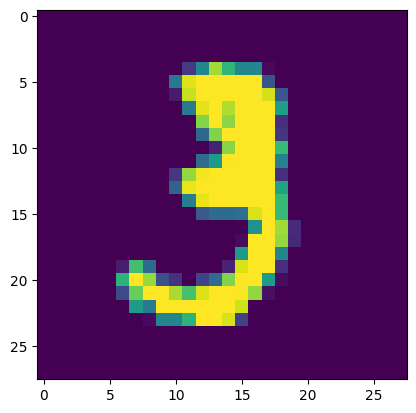

In [6]:
plt.imshow(X_train[10])
print(y_train[10])

Podemos visualizar algunas imágenes del set de entrenamiento usando las siguientes líneas de código:

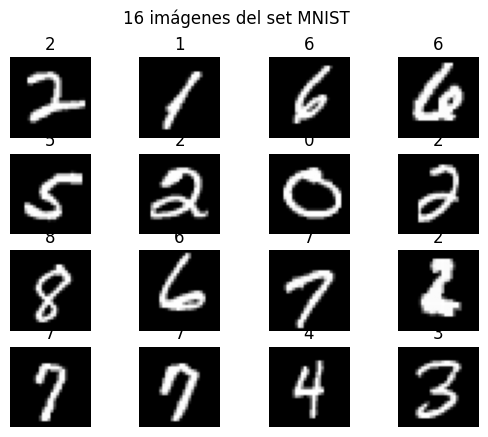

In [7]:
import matplotlib.pyplot as plt
import numpy as np

ids_imgs = np.random.randint(0,X_train.shape[0],16)
for i in range(len(ids_imgs)):
	img = X_train[ids_imgs[i],:,:]
	plt.subplot(4,4,i+1)
	plt.imshow(img, cmap='gray')
	plt.axis('off')
	plt.title(y_train[ids_imgs[i]])
plt.suptitle('16 imágenes del set MNIST')
plt.show()

Con las redes neuronales convencionales, no podemos introducir la imagen como entrada tal como está. Por lo tanto, necesitamos aplanar las imágenes en vectores unidimensionales, cada uno de tamaño 1 x (28 x 28) = 1 x 784.


In [8]:
# aplanar las imágenes en un vector unidimensional

num_pixels = X_train.shape[1] * X_train.shape[2] # encontrar el tamaño de un vector unidimensional

X_train = X_train.reshape(X_train.shape[0], num_pixels).astype('float32') # aplanar imágenes de entrenamiento
X_test = X_test.reshape(X_test.shape[0], num_pixels).astype('float32') # aplanar imágenes de prueba

In [9]:
X_train.shape
X_train[0]

array([  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   

Dado que los valores de los píxeles pueden variar de 0 a 255, normalicemos los vectores para que estén entre 0 y 1.


In [10]:
# normalizar entradas de 0-255 a 0-1
X_train = X_train / 255
X_test = X_test / 255


In [11]:
X_train.shape
X_train[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

Finalmente, antes de comenzar a construir nuestro modelo, recuerda que para la clasificación necesitamos dividir nuestra variable objetivo en categorías. Utilizamos la función to_categorical del paquete Keras Utilities.


Por ejemplo, si la categoría es 0 la representación one-hot correspondiente será el arreglo [1,0,0,0,0,0,0,0,0,0], para la categoría 1 la representación será el arreglo [0,1,0,0,0,0,0,0,0,0] y así sucesivamente.

In [12]:
# codificar salidas en one hot
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

num_classes = y_test.shape[1]
print(num_classes)


10


In [13]:
y_train[0]

array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])

Debemos fijar la semilla del generador aleatorio. Esto debido a que cuando creamos la Red Neuronal en Keras los parámetros de la misma son inicializados con valores aleatorios; para garantizar que siempre que ejecutemos el código lleguemos exactamente al mismo desempeño de la Red se hace necesario introducir la siguiente línea de código:

In [14]:
np.random.seed(1)

## Construir una Red Neuronal


In [15]:
# definir el modelo de clasificacion
def classification_model():
    # create model

    model = Sequential()
    model.add(Input(shape=(num_pixels,)))
    model.add(Dense(num_pixels, activation='relu'))
    model.add(Dense(100, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))

    # compilamos modelo
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

## Entrenar y Probar la Red


In [16]:
# contruir el modelo
model = classification_model()
model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 694,950 (2.65 MB)

 Trainable params: 694,950 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

Además, teniendo en cuenta que el set de entrenamiento contiene 60.000 imágenes, para evitar problemas de almacenamiento en memoria durante el entrenamiento, optaremos por presentar al modelo lotes de tan sólo 1024 imágenes.

In [17]:
# entrenamos el modelo

batch_size = 1024
historia = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=batch_size, verbose=2)

# evaluamos el modelo
scores = model.evaluate(X_test, y_test, verbose=0)

Epoch 1/10
59/59 - 8s - 131ms/step - accuracy: 0.8712 - loss: 0.4708 - val_accuracy: 0.9404 - val_loss: 0.2094
Epoch 2/10
59/59 - 4s - 72ms/step - accuracy: 0.9519 - loss: 0.1693 - val_accuracy: 0.9592 - val_loss: 0.1389
Epoch 3/10
59/59 - 5s - 85ms/step - accuracy: 0.9680 - loss: 0.1122 - val_accuracy: 0.9688 - val_loss: 0.1072
Epoch 4/10
59/59 - 4s - 64ms/step - accuracy: 0.9775 - loss: 0.0808 - val_accuracy: 0.9742 - val_loss: 0.0860
Epoch 5/10
59/59 - 4s - 73ms/step - accuracy: 0.9828 - loss: 0.0609 - val_accuracy: 0.9762 - val_loss: 0.0811
Epoch 6/10
59/59 - 5s - 81ms/step - accuracy: 0.9872 - loss: 0.0466 - val_accuracy: 0.9794 - val_loss: 0.0683
Epoch 7/10
59/59 - 4s - 64ms/step - accuracy: 0.9899 - loss: 0.0368 - val_accuracy: 0.9796 - val_loss: 0.0637
Epoch 8/10
59/59 - 5s - 78ms/step - accuracy: 0.9921 - loss: 0.0293 - val_accuracy: 0.9795 - val_loss: 0.0661
Epoch 9/10
59/59 - 5s - 76ms/step - accuracy: 0.9940 - loss: 0.0236 - val_accuracy: 0.9813 - val_loss: 0.0604
Epoch 10/

Veamos en detalle cómo se comporta el valor de la función de error durante cada iteración.

Text(0.5, 0, 'Iteración')

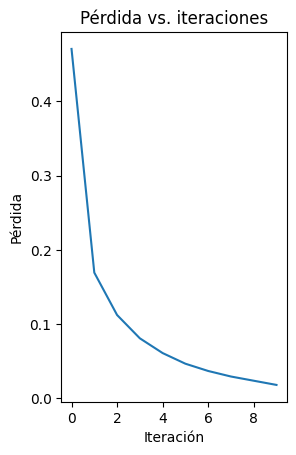

In [18]:
plt.subplot(1,2,1)
plt.plot(historia.history['loss'])
plt.title('Pérdida vs. iteraciones')
plt.ylabel('Pérdida')
plt.xlabel('Iteración')

Por otra parte, si obtenemos una gráfica de la exactitud del modelo vs. el número de iteraciones, esperaríamos observar un comportamiento opuesto al del error: a medida que avanza el entrenamiento la exactitud debería ser cada vez más alta.

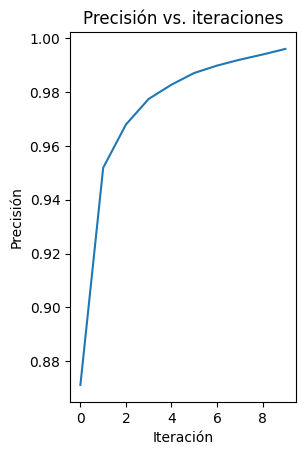

In [19]:
plt.subplot(1,2,2)
plt.plot(historia.history['accuracy'])
plt.title('Precisión vs. iteraciones')
plt.ylabel('Precisión')
plt.xlabel('Iteración')
plt.show()

In [20]:
Y_pred = np.argmax(model.predict(X_test), axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


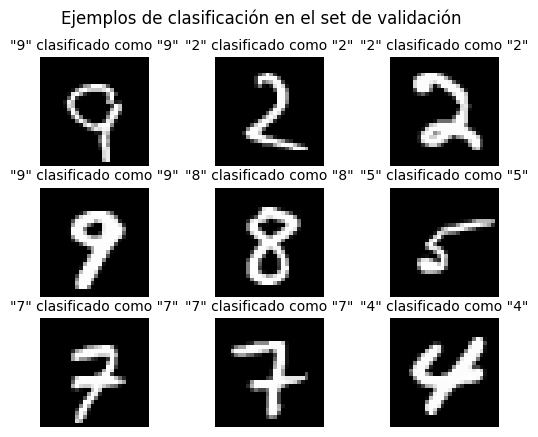

In [21]:
ids_imgs = np.random.randint(0,X_test.shape[0],9)
for i in range(len(ids_imgs)):
	idx = ids_imgs[i]
	img = X_test[idx,:].reshape(28,28)
	cat_original = np.argmax(y_test[idx])
	cat_prediccion = Y_pred[idx]

	plt.subplot(3,3,i+1)
	plt.imshow(img, cmap='gray')
	plt.axis('off')
	plt.title('"{}" clasificado como "{}"'.format(cat_original,cat_prediccion), fontsize=10)
plt.suptitle('Ejemplos de clasificación en el set de validación')
plt.show()

Imprimamos la precisión y el error correspondiente.


In [22]:
print('Accuracy: {}% \n Error: {}'.format(scores[1], 1 - scores[1]))

Accuracy: 0.9810000061988831% 
 Error: 0.018999993801116943


Correr solo 10 épocas podría llevar más de 20 minutos. Pero disfruta de los resultados a medida que se van generando.


A veces, no puedes permitirte reentrenar tu modelo cada vez que quieras usarlo, especialmente si tienes recursos computacionales limitados y entrenar tu modelo puede llevar mucho tiempo. Por lo tanto, con la biblioteca Keras, puedes guardar tu modelo después de entrenarlo. Para hacerlo, usamos el método save.


In [23]:
model.save('classification_model.keras')

Dado que nuestro modelo contiene arreglos de datos multidimensionales, los modelos suelen guardarse como archivos .keras.


Cuando estés listo para usar nuevamente tu modelo, utilizas la función load_model de <strong>keras.saving</strong>.


In [24]:
pretrained_model = keras.saving.load_model('classification_model.keras')

<h3>Ejercicio Práctico 1</h3>


Crea un modelo de red neuronal con 6 capas densas y compara su precisión.


In [25]:
# Ejercicio 1: Modelo con 6 capas densas
from keras.models import Sequential
from keras.layers import Dense, Input
from keras.utils import to_categorical

def classification_model_6_layers():
    model = Sequential()
    model.add(Input(shape=(num_pixels,)))
    model.add(Dense(784, activation='relu'))
    model.add(Dense(512, activation='relu'))
    model.add(Dense(256, activation='relu'))
    model.add(Dense(128, activation='relu'))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Construir y mostrar resumen del modelo
model_6 = classification_model_6_layers()
model_6.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,192,250 (4.55 MB)

 Trainable params: 1,192,250 (4.55 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# Entrenar modelo de 6 capas
batch_size = 1024
historia_6 = model_6.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=batch_size, verbose=2)

# Evaluar modelo
scores_6 = model_6.evaluate(X_test, y_test, verbose=0)
print(f'Accuracy modelo 6 capas: {scores_6[1]*100:.2f}%')
print(f'Error modelo 6 capas: {1 - scores_6[1]:.4f}')

Epoch 1/10
59/59 - 10s - 176ms/step - accuracy: 0.8304 - loss: 0.5901 - val_accuracy: 0.9428 - val_loss: 0.1932
Epoch 2/10
59/59 - 9s - 148ms/step - accuracy: 0.9534 - loss: 0.1627 - val_accuracy: 0.9594 - val_loss: 0.1332
Epoch 3/10
59/59 - 12s - 203ms/step - accuracy: 0.9700 - loss: 0.1034 - val_accuracy: 0.9687 - val_loss: 0.1037
Epoch 4/10
59/59 - 10s - 171ms/step - accuracy: 0.9785 - loss: 0.0718 - val_accuracy: 0.9746 - val_loss: 0.0827
Epoch 5/10
59/59 - 10s - 170ms/step - accuracy: 0.9834 - loss: 0.0536 - val_accuracy: 0.9750 - val_loss: 0.0816
Epoch 6/10
59/59 - 7s - 122ms/step - accuracy: 0.9894 - loss: 0.0355 - val_accuracy: 0.9745 - val_loss: 0.0828
Epoch 7/10
59/59 - 8s - 143ms/step - accuracy: 0.9913 - loss: 0.0289 - val_accuracy: 0.9780 - val_loss: 0.0783
Epoch 8/10
59/59 - 7s - 119ms/step - accuracy: 0.9937 - loss: 0.0209 - val_accuracy: 0.9794 - val_loss: 0.0743
Epoch 9/10
59/59 - 9s - 147ms/step - accuracy: 0.9960 - loss: 0.0134 - val_accuracy: 0.9816 - val_loss: 0.07

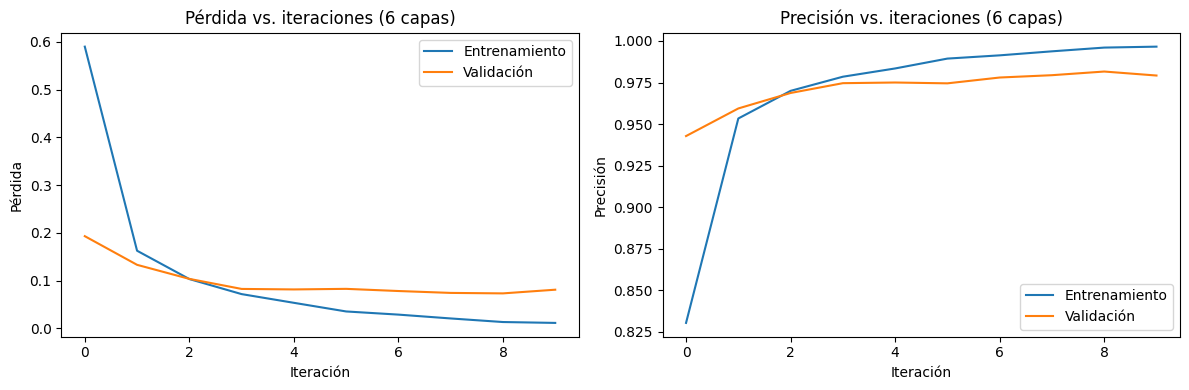

In [27]:
# Gráficas de pérdida y precisión para modelo de 6 capas
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(historia_6.history['loss'], label='Entrenamiento')
plt.plot(historia_6.history['val_loss'], label='Validación')
plt.title('Pérdida vs. iteraciones (6 capas)')
plt.ylabel('Pérdida')
plt.xlabel('Iteración')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(historia_6.history['accuracy'], label='Entrenamiento')
plt.plot(historia_6.history['val_accuracy'], label='Validación')
plt.title('Precisión vs. iteraciones (6 capas)')
plt.ylabel('Precisión')
plt.xlabel('Iteración')
plt.legend()

plt.tight_layout()
plt.show()

In [28]:
# Comparación de resultados
print("=== COMPARACIÓN DE MODELOS ===")
print(f"Modelo original (3 capas):  Accuracy = {scores[1]*100:.2f}%, Error = {1-scores[1]:.4f}")
print(f"Modelo 6 capas:             Accuracy = {scores_6[1]*100:.2f}%, Error = {1-scores_6[1]:.4f}")
print(f"Diferencia:                 Accuracy = {(scores_6[1]-scores[1])*100:+.2f}%")

=== COMPARACIÓN DE MODELOS ===
Modelo original (3 capas):  Accuracy = 98.10%, Error = 0.0190
Modelo 6 capas:             Accuracy = 97.92%, Error = 0.0208
Diferencia:                 Accuracy = -0.18%


<h3>Ejercicio Práctico 2</h3>


Ahora, carga el modelo guardado anteriormente, entrena más durante 10 épocas y verifica la precisión.


In [29]:
# Ejercicio 2: Cargar modelo guardado y entrenar 10 épocas más
from keras.saving import load_model

# Cargar modelo preentrenado
pretrained_model = load_model('classification_model.keras')
print("Modelo cargado exitosamente")
pretrained_model.summary()

Modelo cargado exitosamente


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,084,852 (7.95 MB)

 Trainable params: 694,950 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,389,902 (5.30 MB)

In [30]:
# Entrenar 10 épocas adicionales
batch_size = 1024
historia_extra = pretrained_model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=batch_size, verbose=2)

# Evaluar modelo después del entrenamiento adicional
scores_extra = pretrained_model.evaluate(X_test, y_test, verbose=0)
print(f'Accuracy después de 10 épocas extra: {scores_extra[1]*100:.2f}%')
print(f'Error después de 10 épocas extra: {1 - scores_extra[1]:.4f}')

Epoch 1/10
59/59 - 5s - 78ms/step - accuracy: 0.9971 - loss: 0.0141 - val_accuracy: 0.9815 - val_loss: 0.0616
Epoch 2/10
59/59 - 6s - 99ms/step - accuracy: 0.9981 - loss: 0.0106 - val_accuracy: 0.9815 - val_loss: 0.0571
Epoch 3/10
59/59 - 4s - 72ms/step - accuracy: 0.9988 - loss: 0.0086 - val_accuracy: 0.9821 - val_loss: 0.0601
Epoch 4/10
59/59 - 4s - 63ms/step - accuracy: 0.9992 - loss: 0.0063 - val_accuracy: 0.9814 - val_loss: 0.0606
Epoch 5/10
59/59 - 5s - 77ms/step - accuracy: 0.9993 - loss: 0.0058 - val_accuracy: 0.9825 - val_loss: 0.0603
Epoch 6/10
59/59 - 4s - 74ms/step - accuracy: 0.9998 - loss: 0.0038 - val_accuracy: 0.9809 - val_loss: 0.0632
Epoch 7/10
59/59 - 5s - 77ms/step - accuracy: 0.9998 - loss: 0.0033 - val_accuracy: 0.9823 - val_loss: 0.0633
Epoch 8/10
59/59 - 7s - 111ms/step - accuracy: 0.9999 - loss: 0.0026 - val_accuracy: 0.9817 - val_loss: 0.0641
Epoch 9/10
59/59 - 9s - 149ms/step - accuracy: 1.0000 - loss: 0.0021 - val_accuracy: 0.9828 - val_loss: 0.0633
Epoch 10

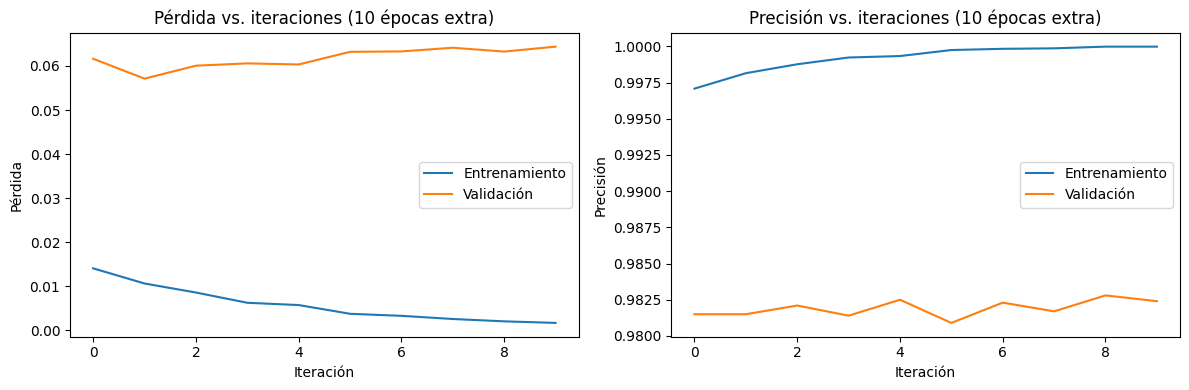

In [31]:
# Gráficas de pérdida y precisión para entrenamiento adicional
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(historia_extra.history['loss'], label='Entrenamiento')
plt.plot(historia_extra.history['val_loss'], label='Validación')
plt.title('Pérdida vs. iteraciones (10 épocas extra)')
plt.ylabel('Pérdida')
plt.xlabel('Iteración')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(historia_extra.history['accuracy'], label='Entrenamiento')
plt.plot(historia_extra.history['val_accuracy'], label='Validación')
plt.title('Precisión vs. iteraciones (10 épocas extra)')
plt.ylabel('Precisión')
plt.xlabel('Iteración')
plt.legend()

plt.tight_layout()
plt.show()

In [32]:
# Comparación de resultados antes y después del entrenamiento adicional
print("=== COMPARACIÓN ANTES Y DESPUÉS DE 10 ÉPOCAS EXTRA ===")
print(f"Modelo original (10 épocas):     Accuracy = {scores[1]*100:.2f}%, Error = {1-scores[1]:.4f}")
print(f"Modelo + 10 épocas extra (20):  Accuracy = {scores_extra[1]*100:.2f}%, Error = {1-scores_extra[1]:.4f}")
print(f"Mejora:                        Accuracy = {(scores_extra[1]-scores[1])*100:+.2f}%")

# Guardar modelo actualizado
pretrained_model.save('classification_model_20_epochs.keras')
print("\nModelo actualizado guardado como 'classification_model_20_epochs.keras'")

=== COMPARACIÓN ANTES Y DESPUÉS DE 10 ÉPOCAS EXTRA ===
Modelo original (10 épocas):     Accuracy = 98.10%, Error = 0.0190
Modelo + 10 épocas extra (20):  Accuracy = 98.24%, Error = 0.0176
Mejora:                        Accuracy = +0.14%

Modelo actualizado guardado como 'classification_model_20_epochs.keras'


### ¡Felicitaciones por completar este laboratorio!